# Fig. 6: Value updating in a principal component of MCC

[AI generated summary] PCA of the composite session aligned on value levels (4 levels of the foraging value) and outcome, separately for each monkey and area:
- **Fig. 6a**: for each principal component (first 100 per monkey and area), the variance of its activity during task engagement explained by the value, and the variance of its trial-to-trial change explained by the outcome (one-way ANOVAs).
- **Fig. 6b**: trajectories of the MCC component most related to both (KA: PC 3, PO: PC 5), by value level and outcome, followed through the next trial.

**How to run:** first build the composite session: `python ../fig4/run_build_composite_session.py meta_rates_value_4x20` in the `fig4` folder (several hours; saved in `results/composite_sessions/`, it is not shared). The trials of the composite session are sampled randomly, so the results differ slightly from those of the paper; in particular, the index of the value-related component (PC 3 and PC 5 in the paper) may change: choose it from Fig. 6a. Then run all cells. Figures are saved in `figs/`.

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
#%% imports
import os

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
import statsmodels.api as sm
import statsmodels.formula.api as smf

from popy.config import COLORS
from popy.plotting.plotting_tools import plot_keypoints

from helpers import load_data_custom, fit_transform_data, compute_explained_var

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_pca_trajectory(pca_dataset, monkey, pca_comp, paper_format=False):
    if paper_format:
        plt.rcParams.update({'font.size': 8})
        lw = 2
        h, w = 1.5 , 3
    else:   
        plt.rcParams.update({'font.size': 18})
        lw = 3
        h, w = 4, 6

    label_encoding = {'value': {0: 'Low', 1: 'Mid', 2: 'High'},
                        'feedback': {0: 'Unrewarded', 1: 'Rewarded'}}

    # Get data
    unit_data_a = pca_dataset.firing_rates.sel(pca_component=pca_comp)

    # if high values are lower, flip the data
    if unit_data_a.sel(trial_id=unit_data_a.value_function == 2).mean().data < unit_data_a.sel(trial_id=unit_data_a.value_function == 0).mean().data:
        unit_data_a.data = -unit_data_a.data

    # substract mean 
    unit_data_a.data = unit_data_a.data - np.mean(unit_data_a.data, axis=0, keepdims=True)

    # Create 3D figure
    fig, ax = plt.subplots(1, 1, figsize=(w, h))

    time_vector = pca_dataset.time.values

    labels = pca_dataset.value_function.values
    labels_2 = pca_dataset.feedback.values
    colors = [COLORS[0], 'grey', COLORS[1]]
    linestyles = {0:'--', 1:'-'}

    # merge labels 1 and 2 into one label (1 for both)
    mapping = {0:0, 1: 1, 2: 2, 3: 2}  # merge labels 1 and 2 into one label (1 for both)
    labels = np.array([mapping[x] for x in labels])

    # Plot the trajectories for each condition
    colors_count = 0
    for i, label in enumerate(np.unique(labels)):
        # Get trials for this condition
        if labels_2 is not None:
            for j, label_2 in enumerate(np.unique(labels_2)):
                    trial_ids = unit_data_a.trial_id[(labels == label) & (labels_2 == label_2)]
                    mean_count_a = np.mean(unit_data_a.sel(trial_id=trial_ids), axis=0)

                    # smooth in time
                    mean_count_a_smooth_data = np.convolve(mean_count_a.values, np.ones(50)/50, mode='same')

                    # Plot the trajectory
                    ax.plot(time_vector, mean_count_a_smooth_data, 
                            label=f'V: {label_encoding["value"][label]}, Fb: {label_encoding["feedback"][label_2]}',
                            color=colors[colors_count], linestyle=linestyles[j], alpha=0.8)
            colors_count += 1
        else:
            trial_ids = unit_data_a.trial_id[labels == label]
            mean_count_a = np.mean(unit_data_a.sel(trial_id=trial_ids), axis=0)

            # Plot the trajectory
            ax.plot(time_vector, mean_count_a.values, label=f'V_t={label}', color=colors[i])

    # Set labels
    ax.set_ylabel(f'PC {unit_data_a.pca_component.data}')
    ax.set_xlabel('Time (s)')

    # Add legend
    # reorder legend labels: put every second on the second column
    handles, labels = ax.get_legend_handles_labels()
    handles_pos = [handles[i] for i in range(len(labels)) if i % 2 == 1]
    handles_neg = [handles[i] for i in range(len(labels)) if i % 2 == 0]
    handles = handles_pos + handles_neg
    labels_pos = [labels[i] for i in range(len(labels)) if i % 2 == 1]
    labels_neg = [labels[i] for i in range(len(labels)) if i % 2 == 0]
    labels = labels_pos + labels_neg
    ax.legend(handles, labels, loc='upper right', fontsize=8, ncol=1, bbox_to_anchor=(1.9, 1))
    #ax.legend(title='history of feedback', loc='upper right')

    plot_keypoints(ax, n_extra_trials=(0, 1), xlabels='short', mark_event='Fb')
    ax.set_xlim([1, 11.1])

    #plt.tight_layout()
    ax.grid(axis='x', alpha=.3)
    sns.despine()

    return fig, ax

---
# Get data

In [4]:
# Load all units
neural_dataset = load_data_custom()
neural_dataset

Removed 226 units with mean firing rate < 1 Hz


<xarray.Dataset>
Dimensions:           (unit: 1866, time: 1500, trial_id: 160)
Coordinates:
    unit_id_original  (unit) int64 ...
    channel           (unit) int64 ...
    monkey            (unit) object ...
    session           (unit) object ...
    area              (unit) object ...
    subregion         (unit) object ...
  * time              (time) float64 0.0 0.01 0.02 0.03 ... 14.97 14.98 14.99
    epoch             (time) float64 ...
  * unit              (unit) object 'ka_010720_LPFC_04_01' ... 'po_310822_MCC...
    feedback          (trial_id) int64 ...
    stay_value        (trial_id) int64 ...
  * trial_id          (trial_id) int64 0 1 2 3 4 5 6 ... 154 155 156 157 158 159
Data variables:
    firing_rates      (trial_id, unit, time) float64 0.2277 0.1585 ... -0.5916
Attributes:
    bin_size:  0.01

In [5]:
# rename stay_value to value_function for clarity??
neural_dataset = neural_dataset.assign_coords(
    value_function=('trial_id', neural_dataset['stay_value'].data),
)
neural_dataset

<xarray.Dataset>
Dimensions:           (unit: 1866, time: 1500, trial_id: 160)
Coordinates: (12/13)
    unit_id_original  (unit) int64 ...
    channel           (unit) int64 ...
    monkey            (unit) object ...
    session           (unit) object ...
    area              (unit) object ...
    subregion         (unit) object ...
    ...                ...
    epoch             (time) float64 ...
  * unit              (unit) object 'ka_010720_LPFC_04_01' ... 'po_310822_MCC...
    feedback          (trial_id) int64 ...
    stay_value        (trial_id) int64 0 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3 3
  * trial_id          (trial_id) int64 0 1 2 3 4 5 6 ... 154 155 156 157 158 159
    value_function    (trial_id) int64 0 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3 3
Data variables:
    firing_rates      (trial_id, unit, time) float64 0.2277 0.1585 ... -0.5916
Attributes:
    bin_size:  0.01

---
# PCA

In [6]:
# Dictionary to hold PCA datasets and components for all monkeys and areas
pca_dataset_all = {'ka': {}, 'po': {}}

# get monkey and area
for monkey in ['ka', 'po']:
    for subregion in ['MCC', 'vLPFC', 'dLPFC']:
        # get data for this subregion and monkey
        neural_dataset_subregion = neural_dataset.sel(unit=(neural_dataset.subregion == subregion) & (neural_dataset.monkey==monkey))
        
        # transform to PCA space
        pca_dataset_subregion, pca_components_subregion = fit_transform_data(neural_dataset_subregion)

        # store results
        pca_dataset_all[monkey][subregion] = pca_dataset_subregion

In [7]:
res = compute_explained_var(pca_dataset_all, n_comps=100)

---
# Fig. 6a, Value- and feedback-related variance of the PCs

In [8]:
res_all = res

/tmp/ipykernel_3437611/1276673176.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


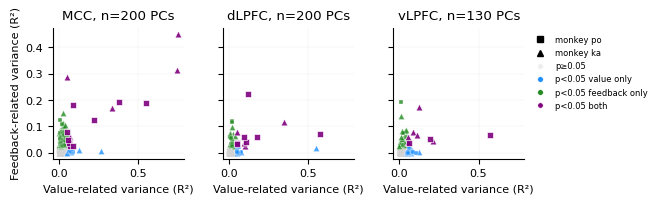

In [9]:
def plot_explained_variance(res_all, n_comps=10000, paperformat=False):
    
    if paperformat:
        plt.rcParams.update({'font.size': 8})
        lw = 1
        s_s, s_t = 13*1.2, 20*1.2
        h, w = 2.5*.85 * .8, 6*.85 * .8 + 2
    else:   
        plt.rcParams.update({'font.size': 18})
        lw = 3
        s = 40
        h, w = 4, 13

    # no gap between subplots
    fig, axs = plt.subplots(1, 3, figsize=(w, h), sharex=True, sharey=True, gridspec_kw={'wspace': 0.3})

    # rectangle and triangle markers for monkeys
    markers = {'po': 's', 'ka': '^'}
    sizes = {'po': s_s, 'ka': s_t}

    for ax_i, area in enumerate(['MCC', 'dLPFC', 'vLPFC']):

        n_comps_all = 0
        for monkey in ['ka', 'po']:
            res = res_all[monkey]
            n_components = np.min((n_comps, len(res[area]['r2s_value'])))
            n_comps_all += n_components

            r2s_value = res[area]['r2s_value'][:n_components]
            pvals_value = res[area]['pvals_value'][:n_components]
            r2s_feedback = res[area]['r2s_feedback'][:n_components]
            pvals_feedback = res[area]['pvals_feedback'][:n_components]

            # Get current axis
            ax = axs[ax_i]
            
            # Separate points by significance pattern
            both_sig = (pvals_value < 0.05) & (pvals_feedback < 0.05)
            value_only = (pvals_value < 0.05) & (pvals_feedback >= 0.05)
            feedback_only = (pvals_value >= 0.05) & (pvals_feedback < 0.05)
            neither_sig = (pvals_value >= 0.05) & (pvals_feedback >= 0.05)
            
            # Plot points with clear visual hierarchy (no numbers!)
            if np.any(neither_sig):
                ax.scatter(r2s_value[neither_sig], r2s_feedback[neither_sig], 
                        c='lightgrey', alpha=0.4, s=sizes[monkey]*0.6, zorder=1, marker=markers[monkey])

            if np.any(value_only):
                ax.scatter(r2s_value[value_only], r2s_feedback[value_only], 
                        c='dodgerblue', alpha=0.8, s=sizes[monkey]*0.8, zorder=2, 
                        edgecolors='white', linewidths=lw*0.3, marker=markers[monkey])

            if np.any(feedback_only):
                ax.scatter(r2s_value[feedback_only], r2s_feedback[feedback_only], 
                        c='forestgreen', alpha=0.8, s=sizes[monkey]*0.8, zorder=2, 
                        edgecolors='white', linewidths=lw*0.3, marker=markers[monkey])

            if np.any(both_sig):
                ax.scatter(r2s_value[both_sig], r2s_feedback[both_sig], 
                        c='purple', alpha=0.9, s=sizes[monkey], zorder=3, 
                        edgecolors='white', linewidths=lw*0.5, marker=markers[monkey])

            # Add diagonal reference line
            #max_val_value = np.max(r2s_value) * 1.1
            #max_val_feedback = np.max(r2s_feedback) * 1.1
            #max_value = max(max_val_value, max_val_feedback)

            '''ax.plot([0, 1], [0, 1], '--', color='darkgrey', 
                    alpha=0.6, linewidth=lw*0.8, zorder=0, label='Unity line')'''
            
        # Clean styling
        ax.set_xlabel('Value-related variance (R²)')
        ax.set_title(f'{area}, n={n_comps_all} PCs')
        
        # Set clean axis limits
        '''ax.set_xlim(-0.005, max_val_value)
        ax.set_ylim(-0.005, max_val_feedback)'''

        # Minimal grid
        ax.grid(True, alpha=0.2, linewidth=lw*0.3)
        
        # Clean spines
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        #ax.spines['left'].set_linewidth(lw*0.5)
        #ax.spines['bottom'].set_linewidth(lw*0.5)
        #ax.tick_params(width=lw*0.5, length=lw*2)

    # Legend only on first subplot
    legend_elements = [
       plt.Line2D([0], [0], marker='s', color='w', label='monkey po', markerfacecolor='k', markersize=4, markeredgecolor='k', markeredgewidth=1),
       plt.Line2D([0], [0], marker='^', color='w', label='monkey ka', markerfacecolor='k', markersize=4, markeredgecolor='k', markeredgewidth=1),
       plt.Line2D([0], [0], marker='o', color='w', label='p≥0.05', markerfacecolor='lightgrey', markersize=4, alpha=0.4),
       plt.Line2D([0], [0], marker='o', color='w', label='p<0.05 value only', markerfacecolor='dodgerblue', markersize=4, markeredgecolor='white', markeredgewidth=lw*0.3),
       plt.Line2D([0], [0], marker='o', color='w', label='p<0.05 feedback only', markerfacecolor='forestgreen', markersize=4, markeredgecolor='white', markeredgewidth=lw*0.3),
       plt.Line2D([0], [0], marker='o', color='w', label='p<0.05 both', markerfacecolor='purple', markersize=4, markeredgecolor='white', markeredgewidth=lw*0.5),
    ]
    
    axs[0].set_ylabel('Feedback-related variance (R²)')

    # legend outside of plot
    axs[2].legend(handles=legend_elements, loc='upper right', 
                  frameon=False, fancybox=False, shadow=False, 
                  fontsize=plt.rcParams['font.size']*0.75, bbox_to_anchor=(2, 1))
    
    plt.tight_layout()
    return fig, axs

fig, axs = plot_explained_variance(res_all, n_comps=2000, paperformat=True)
fig.savefig(os.path.join(FIGS_PATH, 'fig6a_pc_variance.svg'), dpi=300, bbox_inches='tight', transparent=True)

In [10]:
# Export source data (Figure 6a)
from popy.source_data import export_source_data

rows = []
for area in ['MCC', 'dLPFC', 'vLPFC']:
    for monkey in ['ka', 'po']:
        res_area = res_all[monkey][area]
        n_components = np.min((2000, len(res_area['r2s_value'])))  # n_comps of the plot call above
        for pc in range(n_components):
            p_value, p_feedback = res_area['pvals_value'][pc], res_area['pvals_feedback'][pc]
            if p_value < 0.05 and p_feedback < 0.05:
                category = 'Both signals'
            elif p_value < 0.05:
                category = 'Value only'
            elif p_feedback < 0.05:
                category = 'Feedback only'
            else:
                category = 'Non-significant'
            rows.append({'Monkey': monkey.upper(), 'Area': area, 'PC index': pc,
                         'Value-related variance (R2, x)': res_area['r2s_value'][pc], 'p value (value ANOVA)': p_value,
                         'Feedback-related variance (R2, y)': res_area['r2s_feedback'][pc], 'p value (feedback ANOVA)': p_feedback,
                         'Significance (p < 0.05)': category})
fig6a_table = pd.DataFrame(rows)

export_source_data(
    'Figure 6a',
    fig6a_table,
    'PCA of the composite session, per monkey and area (first 100 PCs, or all if fewer; n = '
    + ', '.join(f'{a}: {n}' for a, n in fig6a_table.groupby('Area', sort=False).size().items()) + ' PCs). For each PC: '
    'fraction of variance (eta squared, R2) of its activity in trial t (mean 1-3.5 s) explained by the model-derived value '
    'level (one-way ANOVA, 4 levels; x axis), and fraction of variance of its trial-to-trial change (mean 8.5-11 s minus mean '
    '1-3.5 s) explained by the outcome of trial t (one-way ANOVA; y axis). Colour: significance at p < 0.05; marker: monkey '
    '(triangle: KA, square: PO). PC index starts at 0, as in the axis label of Fig. 6b.',
)

Figure 6a: source data saved (530 rows)


---
# Fig. 6b, Trajectories of the value-related PC in MCC

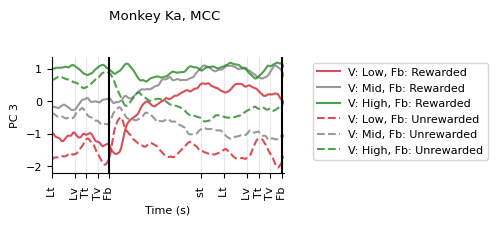

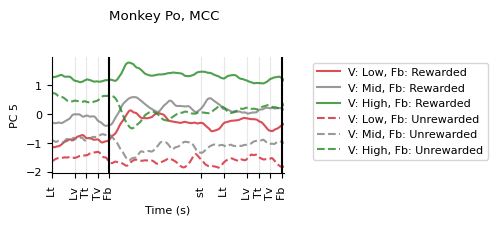

In [11]:
# plot setting: normal, not 3d or interactive

pca_comps = [('ka', 3), ('po', 5)]  # 5 for PO, 3 for KA

# Plot PCA trajectory for each area
for monkey, pca_comp_temp in pca_comps:
    fig, ax = plot_pca_trajectory(pca_dataset_all[monkey]['MCC'], monkey, pca_comp_temp, paper_format=True)
    fig.suptitle(f'Monkey {monkey.capitalize()}, MCC', y=1.2)
    fig.savefig(os.path.join(FIGS_PATH, f'fig6b_{monkey}_MCC_PC{pca_comp_temp}.svg'), dpi=300, bbox_inches='tight', transparent=True)

    # remove legend
    handles, labels = ax.get_legend_handles_labels()
    #ax.legend_.remove()

In [12]:
# Export source data (Figure 6b)
from popy.source_data import export_source_data

value_levels = {0: 'Low', 1: 'Mid', 2: 'High', 3: 'High'}  # merging of the 4 value levels, as in plot_pca_trajectory
fig6b_tables, n_trials = {}, []
for monkey, pca_comp_temp in pca_comps:
    # redraw the panel with the same function and arguments (not shown), and read the plotted (smoothed) trajectories
    fig_tmp, ax_tmp = plot_pca_trajectory(pca_dataset_all[monkey]['MCC'], monkey, pca_comp_temp, paper_format=True)
    plt.close(fig_tmp)
    lines = [line for line in ax_tmp.get_lines() if line.get_label().startswith('V: ')]
    time = lines[0].get_xdata()
    in_view = (time >= ax_tmp.get_xlim()[0]) & (time <= ax_tmp.get_xlim()[1])  # displayed time window
    table = {'Time from the start of trial t (s)': time[in_view]}
    for line in lines:  # label: 'V: <value level>, Fb: <outcome>'
        assert np.array_equal(line.get_xdata(), time)
        value_level, outcome = [part.split(': ')[1] for part in line.get_label().split(', ')]
        table[f'PC {pca_comp_temp}, value {value_level}, {outcome.lower()} (arb. units)'] = line.get_ydata()[in_view]
    fig6b_tables[f'Monkey {monkey.upper()}, MCC, PC {pca_comp_temp}'] = pd.DataFrame(table)

    # number of trials per condition (for the description)
    pca_dataset = pca_dataset_all[monkey]['MCC']
    counts = pd.crosstab([value_levels[v] for v in pca_dataset.value_function.values], pca_dataset.feedback.values)
    n_trials.append(f'{monkey.upper()}: ' + ', '.join(f'{level} {counts.loc[level, 0]}/{counts.loc[level, 1]}' for level in ['Low', 'Mid', 'High']))

export_source_data(
    'Figure 6b',
    fig6b_tables,
    'Population trajectories in MCC (composite session) along the principal component most related to value and feedback in '
    'Fig. 6a (' + ', '.join(f'{m.upper()}: PC {c}' for m, c in pca_comps) + '; projection of the z-scored firing rates, '
    'arbitrary units; sign set so that high value is above low value; mean over all '
    'trials subtracted at each time point), averaged over the trials of each value level of trial t (model-derived value in 4 '
    'bins of [0, 1]: Low = 0-0.25, Mid = 0.25-0.5, High = 0.5-1) and outcome of trial t, smoothed with a 0.5 s (50-sample) '
    'moving average. n trials (unrewarded/rewarded): ' + '; '.join(n_trials) + '. Time from the start of trial t: Lt(t) at 1 s, '
    'Fb(t) at 3.5 s, Lt(t+1) at 8.5 s, Fb(t+1) at 11 s; only the displayed window (1-11.1 s) is included.',
)

Figure 6b: source data saved (1011 rows, 1011 rows)
